# BIOT-SAVART LAW WITH FINITE DIFFERENCE

In [1]:
from matplotlib import pyplot as plt
import numpy as np

The equations of magnetostatics:

$$ \nabla \times \vec{B} = \mu_0 \vec{J} $$

$$ \nabla \cdot \vec{B}  = 0 $$

The second equation gives us that

$$ \vec{B} = \nabla \times \vec{A}$$

Plugging this into the first equation gives us that

$$ \nabla (\nabla \cdot \vec{A}) - \nabla^2 \vec{A} = \mu_0 \vec{J}$$

Choosing the Lorenz gauge (Coulomb gauge for magnetostatics) gives us that

$$ \nabla^2 \vec{A} =  - \mu_0 \vec{J}$$



Pick $\vec{J} = (0,0,I \delta(x)\delta(y))$ for a current moving in the z-direction. This means that $\vec{A} = (0,0,A^z)$.

Away from the wire we solve the source-free Poisson equation Laplace equation. At the boundaries of the computational domain we use the analytical solution to supply boundary conditions.



$$ \nabla^2 A^z = 0 $$

$$ x_{min} \leq  x \leq x_{max}, \quad y_{min} \leq y \leq y_{max } $$

$$ A^z_{i,j-1} + A^z_{i,j+1} + A^z_{i-1,j} + A^z_{i+1,j} - 6 A^z_{i,j} = -A^z_{i,j,k-1} - A^z_{i,j,k+1}$$

Let us use the analytical solution for $\vec{B} = \frac{\mu_0 I}{2 \pi r} \hat{\phi}$ to solve for $\vec{A}$. In Cartesian components we have that

$$ \vec{B} = - \frac{\mu_0 I}{2 \pi r^2} y \hat{i} + \frac{\mu_0 I}{2 \pi r^2} x \hat{j}$$

Since $\vec{A} = (0,0,A^z)$ we get

$$ B^x = \frac{\partial A^z}{\partial y}, \quad B^y = - \frac{\partial A^z}{\partial x}$$

Solving the above system simultaneously yields that

$$ A^z = - \frac{\mu_0 I}{2 \pi}ln\left( \frac{r}{r_0}\right)$$

where $r_0$ is chosen arbitrarily.

Note that since $A^z$ has no z-dependence, we can write the stencil as follows:

$$ A^z_{i,j-1} + A^z_{i,j+1} + A^z_{i-1,j} + A^z_{i+1,j} - 4 A^z_{i,j} = 0 $$

In [2]:
xmin = 1.
xmax = 3.

ymin = 1.
ymax = 3.

N = 100

h = (xmax - xmin)/(N - 1)

In [3]:
print(h)

0.020202020202020204


In [24]:
mu0 = 1.
I = 1.
r0 = 2.

def calc_Az(x,y):
    r = np.sqrt(x**2. + y**2.)
    return -(mu0*I/(2*np.pi))*np.log(r/r0)

def calc_B(x,y): #coefficient of phihat in cylindrical coordinates
    r = np.sqrt(x**2. + y**2.)
    return (mu0*I)/(2*np.pi*r)

In [11]:
def solve_poisson_equation():

    #we know that the diagonal will be -6 everywhere

    L = -4*np.eye(N**2)

    R = np.zeros(N**2)

    x_and_y = []

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
            
            #calculate x and y
            x = xmin + (i-1)*h
            y = ymin + (j-1)*h
            x_and_y.append([x,y])

            #calculate indx
            indx = indx+1

            #check each term individually
            if 1<=indx<=N:
                R[indx-1] = R[indx-1] - calc_Az(x - h,y)
            else:
                L[indx-1, indx-1 -N] = 1.

            if N**2 - N + 1<=indx<=N**2:
                R[indx-1] = R[indx-1] - calc_Az(x + h ,y)
            else:
                L[indx-1, indx-1+N] = 1.

            if (indx-1)%N == 0:
                R[indx-1] = R[indx-1] - calc_Az(x, y-h,)
            else:
                L[indx-1,indx-1-1] = 1.
            
            if indx%N == 0:
                R[indx-1] = R[indx-1] - calc_Az(x, y+h)
            else:
                L[indx-1,indx-1+1] = 1.


    Az = np.linalg.solve(L,R)

   
    return np.array(x_and_y), Az




In [12]:
x_and_y, Az = solve_poisson_equation()

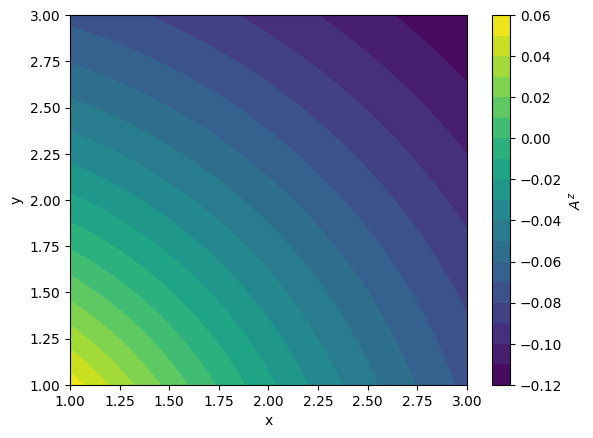

In [18]:
x = x_and_y[:,0]
y = x_and_y[:,1]

plt.figure()
plt.tricontourf(x, y, Az, levels=20)
plt.colorbar(label=r'$A^z$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [14]:
Az_analytical = calc_Az(x,y)

err_Az = Az - Az_analytical

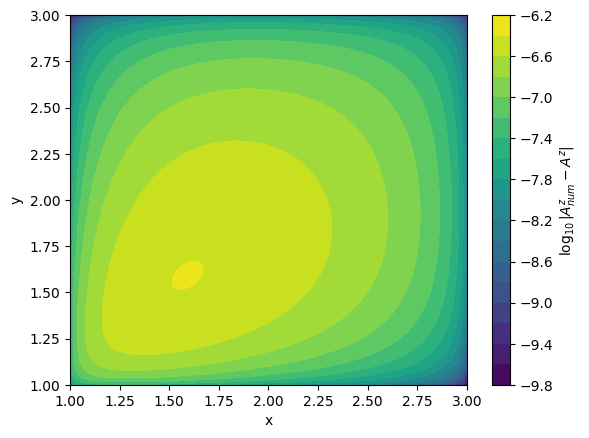

In [19]:
plt.figure()
plt.tricontourf(x, y, np.log10(np.abs(err_Az)), levels=20)
plt.colorbar(label=r'$\log_{10}|A^z_{num} - A^z|$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Calculate Magnetic Field

In [20]:
def calc_magnetic_field(x_and_y, Az):

    Bx = np.zeros(N**2)
    By = np.zeros(N**2)

    x = x_and_y[:,0]
    y = x_and_y[:,1]

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
    
            #calculate indx
            indx = indx+1

            #then check each derivative individually
            if 1<=indx<=N: #do forward derivative
                By[indx-1] =  - (-3*Az[indx-1] + 4*Az[indx-1+N] - Az[indx-1+2*N])/(2*h)   
            elif N**2 - N + 1<=indx<=N**2: #do backward derivative
                By[indx-1] =  - (3*Az[indx-1]- 4*Az[indx-1-N] + Az[indx-1-2*N])/(2*h) 
            else:
                By[indx-1] = - (Az[indx-1 +N] -  Az[indx-1 -N])/(2*h)

           

            if (indx-1)%N == 0: #forward derivative
                Bx[indx-1] =   (-3*Az[indx-1] + 4*Az[indx-1+1] - Az[indx-1+2])/(2*h) 
            elif indx%N == 0: #backward derivative
                Bx[indx-1] =  (3*Az[indx-1]- 4*Az[indx-1-1] + Az[indx-1-2])/(2*h)  
            else:
                Bx[indx-1] =  (Az[indx-1+1] -  Az[indx-1-1])/(2*h)
            
          
    
    return Bx, By


In [21]:
Bx, By = calc_magnetic_field(x_and_y, Az)

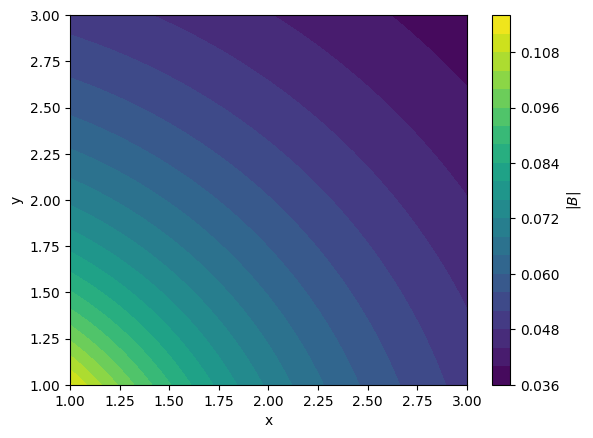

In [22]:
plt.figure()
plt.tricontourf(x, y, np.sqrt(Bx**2 + By**2), levels=20)
plt.colorbar(label=r'$|B|$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [25]:
B_analytical = calc_B(x,y)

B_err =  np.sqrt(Bx**2. + By**2)- B_analytical 

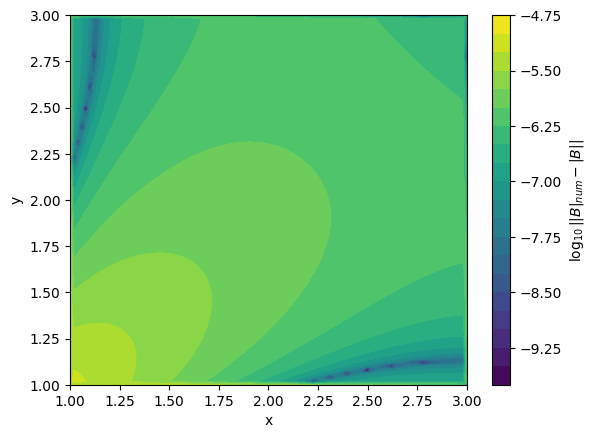

In [26]:
plt.figure()
plt.tricontourf(x, y, np.log10(np.abs(B_err)), levels=20)
plt.colorbar(label=r'$\log_{10}| |B|_{num} - |B||$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Check that Divergence of Magnetic Field Vanishes

In [27]:
def calc_div_B(x_and_y, Bx, By):

    Bx_x = np.zeros(N**2)
    By_y = np.zeros(N**2)
    

    x = x_and_y[:,0]
    y = x_and_y[:,1]

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
    
            #calculate indx
            indx = indx+1

            #then check each derivative individually
            if 1<=indx<=N: #do forward derivative
                Bx_x[indx-1] =  (-3*Bx[indx-1] + 4*Bx[indx-1+N] - Bx[indx-1+2*N])/(2*h)  
            elif N**2 - N + 1<=indx<=N**2: #do backward derivative
                Bx_x[indx-1] =   (3*Bx[indx-1]- 4*Bx[indx-1-N] + Bx[indx-1-2*N])/(2*h) 
            else:
                Bx_x[indx-1] =  (Bx[indx-1 +N] -  Bx[indx-1 -N])/(2*h)

           

            if (indx-1)%N == 0: #forward derivative
                By_y[indx-1] =    (-3*By[indx-1] + 4*By[indx-1+1] - By[indx-1+2])/(2*h) 
            elif indx%N == 0: #backward derivative
                By_y[indx-1] =   (3*By[indx-1]- 4*By[indx-1-1] + By[indx-1-2])/(2*h) 
            else:
                By_y[indx-1] =  (By[indx-1+1] -  By[indx-1-1])/(2*h)
            
          
    
    return Bx_x + By_y

In [28]:
div_B = calc_div_B(x_and_y, Bx, By)

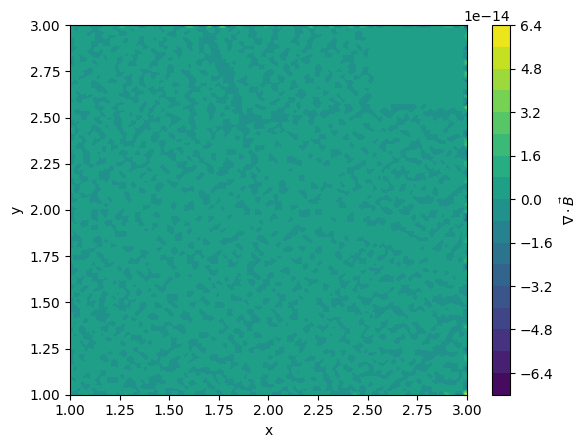

In [30]:
plt.figure()
plt.tricontourf(x, y, div_B, levels=20)
plt.colorbar(label=r'$ \nabla \cdot \vec{B}$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()